# 📘 Explained copy — 07 High-frequency trading (Module 7)

Study copy of `notebooks/07_hft.ipynb`. Original cells unchanged (with outputs); above each is an **Explanation**:
*what it does · why this method · input → output · how to read the output vs alternatives*.

**Story for the report.** 120,000 limit-order-book events (10 stocks × 20 days). Label = UP/DOWN/FLAT of the next
100 ms mid-price move (FLAT if |move| < 1.2 bp). **Order-book imbalance (OBI) correlates 0.51** with the next move.
We split **by trading day** (12 train / 4 validation / 4 test), compare multinomial logistic, RF and GB on **macro-F1**:
all ≈ 0.44 vs no-skill 0.20 — but **level with a one-line OBI-sign rule**, so the simplest (logistic) is chosen.
A threshold trading rule (θ = 0.55, chosen on validation) earns **1.65 bp net/trade, ₹6.3 lakh/day** on test, but
**doubling costs or 1-event latency turns it negative** → no material capital for prop HFT. The robust use is
**execution timing**: ≈ 7 bp better fills per child order.

> ### 📘 Explanation — cell 0
> **What it is.** Business question (can the order book predict the next 100 ms move, and is it worth trading?), chain,
> tasks, leakage rules and validation.
>
> **Why split by trading day.** Timestamps are only to the minute, so events within a minute cannot be ordered by time;
> whole days are clean, non-overlapping time blocks → earlier days train, later days test (no look-ahead, no intraday
> leakage between neighbouring events).
> **Leakage:** `Future_Return_100ms` / `Future_Price_100ms` are the answer — used only to build labels and score P&L.

# 07. High-frequency trading: can the order book predict the next move? (Module 7)

**Business question (Head of Trading).** Can ML use limit-order-book information to predict short-horizon (100 ms)
price moves, and is the signal worth enough to trade or to improve the execution of large orders?

**Chain.** Order-book snapshot → probability of UP / DOWN / FLAT in the next 100 ms (ML) → trade only when confident
→ profit per trade after spread and fees → stress with higher costs and latency → capital and limits for an HFT line.

**Brief tasks covered.**
1. Short-horizon direction prediction: target `Price_Move_Class` (FLAT = NO_MOVE), compare models.
2. Turn the probabilities into a trading signal and backtest it: does it generate enough economic value?

**Leakage rules (from the brief).** `Future_Return_100ms` and `Future_Price_100ms` describe the future. They are
used **only** to build the label and to score trades, never as features.

**Validation.** Split **by trading day** (earlier days train, later days test). Rows inside a day are kept in file
order, because timestamps only go to the minute.

> ### 📘 Explanation — cell 1
> **What it does.** Loads helpers and sets output folders for Module 7.

In [1]:
import sys; sys.path.insert(0, '../src')   # make the shared helper module importable
from novafin import *                       # shared assumptions, loaders, metrics, plot style
RES, FIG = use_module('07')                 # this module's output folders (results/ and figures/)

NovaFin helpers loaded. Root: C:\Users\pravi\PG IITB\Machine Learning in Finance\capstone project solution\novafin_capstone
Outputs -> results/Module_07_HFT/ and figures/Module_07_HFT/


> ### 📘 Explanation — cell 2
> **What it does.** Imports multinomial logistic regression, RF, HistGB, scaler, and multi-class metrics: **macro-F1**, accuracy, **log-loss**, confusion matrix.

In [2]:
from sklearn.linear_model import LogisticRegression                     # model 1: multinomial logistic
from sklearn.ensemble import RandomForestClassifier                     # model 2: bagged trees
from sklearn.ensemble import HistGradientBoostingClassifier             # model 3: boosted trees
from sklearn.preprocessing import StandardScaler                        # scaling for the logistic model
from sklearn.pipeline import make_pipeline                              # prep + model
from sklearn.metrics import f1_score, accuracy_score, log_loss, confusion_matrix, classification_report
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)

> ### 📘 Explanation — cell 3
> **What it does.** Assumptions: round-trip fees **0.5 bp**, notional **₹10 lakh per trade**, leakage column list, class order (DOWN, FLAT, UP).

In [3]:
FEE_BP = 0.5          # exchange + clearing + regulatory fees, round trip, in basis points (assumption)
NOTIONAL = 1e6        # ₹10 lakh traded per signal (assumption, to express P&L in rupees)
LEAK = ['Future_Return_100ms', 'Future_Price_100ms']    # never features
CLASSES = ['DOWN', 'FLAT', 'UP']                         # alphabetical, as scikit-learn orders them

> ### 📘 Explanation — cell 4
> **What it does.** Loads 120,000 events, keeps the file order as `Event_No` (true event order within a minute), parses the
> trading day, sorts by day → stock → event.
>
> **Output.** (120,000, 35), 10 stocks, 20 days, 2026-01-05 → 2026-01-30.

In [4]:
hft = load('hft')                                                            # 120,000 order-book events
hft['Event_No'] = np.arange(len(hft))                                        # file order = event order within a minute
hft['Day'] = pd.to_datetime(hft.Trading_Day, format='%d-%m-%Y')              # trading day as a date
hft = hft.sort_values(['Day', 'Stock', 'Event_No']).reset_index(drop=True)   # event order within each stock-day
print(hft.shape, '|', hft.Stock.nunique(), 'stocks |', hft.Day.nunique(), 'days |', hft.Day.min().date(), 'to', hft.Day.max().date())

(120000, 35) | 10 stocks | 20 days | 2026-01-05 to 2026-01-30


> ### 📘 Explanation — cell 5
> **Section header** – audit and exploration.

## 1. Audit and exploration

> ### 📘 Explanation — cell 6
> **What it does.** Missing values, class balance, event types, and min/max/mean of the future return (in bp) inside each class.
>
> **Output.** 0 missing; DOWN 41.9% / UP 41.7% / FLAT 16.4%; limit 57k, market 32k, cancel 30k. FLAT spans exactly
> −1.20 to +1.20 bp.
>
> **Why this check.** Reverse-engineering the label shows the rule: |move| < 1.2 bp ⇒ FLAT.

In [5]:
print('Missing values:', int(hft.isna().sum().sum()))
print('Class balance:', hft.Price_Move_Class.value_counts(normalize=True).round(3).to_dict())
print('Event types  :', hft.Event_Type.value_counts().to_dict())
# How is the label built? Look at the future return range inside each class.
hft.groupby('Price_Move_Class').Future_Return_100ms.agg(['min', 'max', 'mean', 'count']).mul([1e4, 1e4, 1e4, 1]).round(2)

Missing values: 0
Class balance: {'DOWN': 0.419, 'UP': 0.417, 'FLAT': 0.164}
Event types  : {'LIMIT_ORDER': 57473, 'MARKET_ORDER': 32406, 'CANCEL': 30121}


,min,max,mean,count
Price_Move_Class,,,,
DOWN,-31.62,-1.20,-5.56,50294.0
FLAT,-1.20,1.20,0.01,19661.0
UP,1.20,27.93,5.35,50045.0


> ### 📘 Explanation — cell 7
> **Label rule.** FLAT if |next-100 ms return| < 1.2 bp, else UP/DOWN (1 bp = 0.01%).

The label is a simple rule on the next-100 ms mid-price return: **FLAT if |return| < 1.2 bp**, otherwise UP or DOWN.
(bp = basis point = 0.01%.)

> ### 📘 Explanation — cell 8
> **What it does.** Absolute next move and quoted spread in bp.
>
> **Output.** Average |move| **4.66 bp** vs average spread **1.34 bp**.
>
> **How to read.** Moves are 3.5× the spread — in real markets the next tick is usually *smaller* than the spread. This
> synthetic market is unusually generous → all profits must be stress-tested.

In [6]:
hft['Abs_Move_bp'] = hft.Future_Return_100ms.abs() * 1e4                # size of the next move in bp
hft['Spread_bp'] = hft.Relative_Spread * 1e4                            # quoted spread in bp
print('average |100 ms move| =', round(hft.Abs_Move_bp.mean(), 2), 'bp | average spread =', round(hft.Spread_bp.mean(), 2), 'bp')

average |100 ms move| = 4.66 bp | average spread = 1.34 bp


> ### 📘 Explanation — cell 9
> **What it does.** (1) Stacked share of next move by OBI decile; (2) histogram of |move| vs spread; (3) class mix per stock. Saves `hft_eda.png`. Panel 1 shows UP share rising monotonically with OBI — the core microstructure signal.

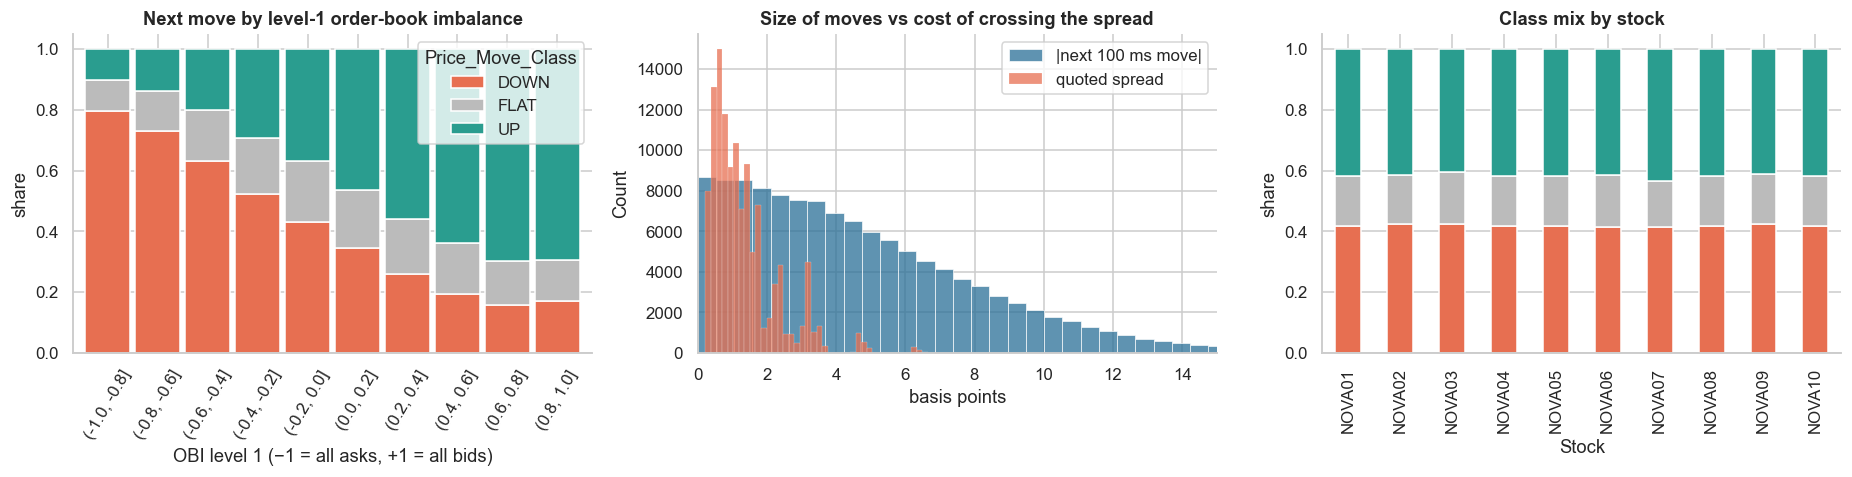

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
obi_bin = pd.cut(hft.OBI_Level1, np.linspace(-1, 1, 11))                       # 10 bins of order-book imbalance
share = pd.crosstab(obi_bin, hft.Price_Move_Class, normalize='index')[['DOWN', 'FLAT', 'UP']]
share.plot(kind='bar', stacked=True, ax=ax[0], color=['#e76f51', '#bbbbbb', '#2a9d8f'], width=0.9)
ax[0].set(title='Next move by level-1 order-book imbalance', xlabel='OBI level 1 (−1 = all asks, +1 = all bids)', ylabel='share')
ax[0].tick_params(axis='x', rotation=60)
sns.histplot(hft.Abs_Move_bp, bins=60, ax=ax[1], color='#2a6f97', label='|next 100 ms move|')
sns.histplot(hft.Spread_bp, bins=60, ax=ax[1], color='#e76f51', label='quoted spread')
ax[1].set(title='Size of moves vs cost of crossing the spread', xlabel='basis points', xlim=(0, 15)); ax[1].legend()
hft.groupby('Stock').Price_Move_Class.value_counts(normalize=True).unstack()[['DOWN', 'FLAT', 'UP']].plot(
    kind='bar', stacked=True, ax=ax[2], color=['#e76f51', '#bbbbbb', '#2a9d8f'], legend=False)
ax[2].set(title='Class mix by stock', ylabel='share')
plt.tight_layout(); savefig('hft_eda'); plt.show()

> ### 📘 Explanation — cell 10
> **What it does.** Pearson correlation of book features with the next 100 ms return.
>
> **Output.** **OBI_Level1 0.513**, OBI_3Level 0.513, **Microprice − Mid 0.479**; cancellation rate −0.08, spread −0.07, volatility −0.06; depth ≈ 0.
>
> **How to read.** Imbalance and microprice are extremely strong by market standards (real correlations are ~0.05–0.1).
> Microprice = imbalance-weighted mid, so it carries the same information.

In [8]:
corr = hft[['OBI_Level1', 'OBI_3Level', 'Microprice_Minus_Mid', 'Order_Arrival_Rate', 'Cancellation_Rate',
            'Short_Term_Volatility', 'Spread_bp', 'Total_Depth', 'Future_Return_100ms']].corr()['Future_Return_100ms'].drop('Future_Return_100ms')
corr.sort_values().round(3).to_frame('correlation with next 100 ms return')

,correlation with next 100 ms return
Cancellation_Rate,-0.081
Spread_bp,-0.071
Short_Term_Volatility,-0.063
Order_Arrival_Rate,-0.024
Total_Depth,0.004
Microprice_Minus_Mid,0.479
OBI_Level1,0.513
OBI_3Level,0.513


> ### 📘 Explanation — cell 11
> **EDA conclusion.** OBI ≈ 0.5 correlation; moves ≫ spread ⇒ generous synthetic market; stress-test before believing any profit.

**Reading the EDA.**
- When bids outweigh asks (OBI near +1) the next move is mostly UP, and vice versa. Imbalance correlates about **0.5**
  with the next return: a very strong signal by market standards.
- The average 100 ms move (≈ 4.7 bp) is **several times** the spread (≈ 1.3 bp). In real markets the next tick is
  usually *smaller* than the spread. So this synthetic market is unusually generous, and any profit must be stress-tested
  with higher costs and latency before it is believed.

> ### 📘 Explanation — cell 12
> **Features (no look-ahead).** Supplied book features + scale-free versions (microprice−mid in bp, log depth, level-2/3 imbalances) + recent history of the same stock (previous events only, via `shift` within stock-day): mid change, previous OBI, OBI change, buy share of last 10 trades.

## 2. Features (no look-ahead)
- Supplied book features: imbalance (level 1 and 3 levels), microprice − mid, spread, depth, arrival and cancellation
  rates, short-term volatility, trade volume and side, event type.
- Scale-free versions: microprice − mid **in bp of the mid**, depth on a log scale, level-2/3 imbalances.
- **Recent history of the same stock** (previous events only, using `shift` within stock-day): change in mid since the
  previous event, previous imbalance, and the share of buy trades in the last 10 events (order-flow pressure).

> ### 📘 Explanation — cell 13
> **What it does.** Builds 18 features; history features use `groupby(['Day','Stock'])` + `shift(1)` so they never cross
> days/stocks and use only past events; `assert` guarantees no leakage column is a feature.
>
> **Why these.** **OBI** = (bid size − ask size)/(bid + ask) = buying vs selling pressure; **microprice** tilts the mid toward the
> side with less depth; **OFI-style** change in OBI shows pressure building; buy share of trades = order-flow pressure.
> These are the taught microstructure features (OBI/OFI, microprice).
>
> **Output.** 18 features; leakage columns excluded.

In [9]:
g = hft.groupby(['Day', 'Stock'])                                                   # history never crosses days or stocks
hft['MPM_bp'] = hft.Microprice_Minus_Mid / hft.Mid_Price * 1e4                       # microprice signal in bp
hft['Log_Depth'] = np.log(hft.Total_Depth)                                           # depth, log scale
hft['OBI_L2'] = (hft.Bid_Size_2 - hft.Ask_Size_2) / (hft.Bid_Size_2 + hft.Ask_Size_2)   # level-2 imbalance
hft['OBI_L3'] = (hft.Bid_Size_3 - hft.Ask_Size_3) / (hft.Bid_Size_3 + hft.Ask_Size_3)   # level-3 imbalance
hft['Buy_Trade'] = (hft.Trade_Side == 'BUY').astype(int)                             # aggressor side of the last trade
hft['Mid_Change_bp'] = g.Mid_Price.pct_change().fillna(0) * 1e4                      # move since the previous event
hft['Prev_OBI'] = g.OBI_Level1.shift(1).fillna(0)                                    # imbalance one event ago
hft['OBI_Change'] = hft.OBI_Level1 - hft.Prev_OBI                                    # is pressure building?
hft['Buy_Share_10'] = g.Buy_Trade.transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean()).fillna(0.5)
hft['Is_Market'] = (hft.Event_Type == 'MARKET_ORDER').astype(int)                    # event type flags
hft['Is_Cancel'] = (hft.Event_Type == 'CANCEL').astype(int)

FEATURES = ['OBI_Level1', 'OBI_3Level', 'OBI_L2', 'OBI_L3', 'MPM_bp', 'Spread_bp', 'Log_Depth', 'Order_Arrival_Rate',
            'Cancellation_Rate', 'Short_Term_Volatility', 'Trade_Volume', 'Buy_Trade', 'Is_Market', 'Is_Cancel',
            'Mid_Change_bp', 'Prev_OBI', 'OBI_Change', 'Buy_Share_10']
assert not set(FEATURES) & set(LEAK)                                                 # leakage guard
print(len(FEATURES), 'features; leakage columns excluded:', LEAK)

18 features; leakage columns excluded: ['Future_Return_100ms', 'Future_Price_100ms']


> ### 📘 Explanation — cell 14
> **Section header** – split by trading day.

## 3. Split by trading day

> ### 📘 Explanation — cell 15
> **What it does.** Days 1–12 train, 13–16 validation, 17–20 test.
>
> **Output.** Train 72,055 rows, validation 24,047, test 23,898; class mix stable (UP ≈ 41.5%, FLAT ≈ 16%).

In [10]:
days = sorted(hft.Day.unique())                                    # 20 trading days
train_days, val_days, test_days = days[:12], days[12:16], days[16:]
part = lambda ds: hft[hft.Day.isin(ds)]
train, val, test = part(train_days), part(val_days), part(test_days)
for n, d in [('train', train), ('validation', val), ('test', test)]:
    print(f'{n:<11} {d.Day.min().date()} to {d.Day.max().date()} | rows {len(d):>6} | UP {np.mean(d.Price_Move_Class == "UP"):.3f} | FLAT {np.mean(d.Price_Move_Class == "FLAT"):.3f}')

train       2026-01-05 to 2026-01-20 | rows  72055 | UP 0.417 | FLAT 0.164
validation  2026-01-21 to 2026-01-26 | rows  24047 | UP 0.414 | FLAT 0.160
test        2026-01-27 to 2026-01-30 | rows  23898 | UP 0.419 | FLAT 0.166


> ### 📘 Explanation — cell 16
> **Why macro-F1.** It averages F1 of the 3 classes equally, so FLAT (16%) counts as much as UP and DOWN — accuracy would be dominated by the two large classes.

## 4. Direction models (ML Task 1)
**Macro-F1** averages the F1 score of the three classes equally, so the smaller FLAT class counts as much as UP and DOWN.

> ### 📘 Explanation — cell 17
> **What it does.** Fits multinomial logistic (scaled), RF (200 trees, min leaf 50), GB (depth 4, lr 0.08, 300 iterations) on the 12 training days.
>
> **Why min leaf 50 for RF.** 72k rows of very noisy labels; large leaves average out noise.

In [11]:
models = {
    'Multinomial logistic': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0)),
    'Random forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=50, max_features='sqrt', n_jobs=-1, random_state=SEED),
    'Gradient boosting': HistGradientBoostingClassifier(max_depth=4, learning_rate=0.08, max_iter=300, random_state=SEED),
}
fitted = {n: m.fit(train[FEATURES], train.Price_Move_Class) for n, m in models.items()}   # fit on the 12 training days

> ### 📘 Explanation — cell 18
> **What it does.** `class_report()` → macro-F1, accuracy, log-loss and per-class recall from probabilities; evaluated on validation.
>
> **Output.** All three: macro-F1 **0.443**, accuracy 0.612, log-loss ≈ 0.898–0.899, recall DOWN ≈ 0.72, UP ≈ 0.73, **FLAT 0.0**.
>
> **How to read.** Identical performance ⇒ the signal is essentially linear in OBI; complexity adds nothing. FLAT is never
> the most likely class (it is the smallest and sits in the middle) — fine for trading, which acts only on UP/DOWN.

In [12]:
def class_report(y, proba, name):
    """Macro-F1, accuracy, log-loss and recall per class from predicted probabilities."""
    yhat = np.array(CLASSES)[proba.argmax(1)]                       # most likely class
    rec = pd.Series(confusion_matrix(y, yhat, labels=CLASSES).diagonal() / pd.Series(y).value_counts().reindex(CLASSES).values, index=CLASSES)
    return pd.Series({'Macro-F1': f1_score(y, yhat, average='macro'), 'Accuracy': accuracy_score(y, yhat),
                      'Log-loss': log_loss(y, proba, labels=CLASSES),
                      'Recall DOWN': rec['DOWN'], 'Recall FLAT': rec['FLAT'], 'Recall UP': rec['UP']}, name=name)

val_proba = {n: m.predict_proba(val[FEATURES]) for n, m in fitted.items()}
val_rep = pd.DataFrame({n: class_report(val.Price_Move_Class, p, n) for n, p in val_proba.items()}).T
val_rep.round(4)

,Macro-F1,Accuracy,Log-loss,Recall DOWN,Recall FLAT,Recall UP
Multinomial logistic,0.4431,0.6116,0.8990,0.7188,0.0,0.7374
Random forest,0.4432,0.6116,0.8988,0.7217,0.0,0.7345
Gradient boosting,0.4432,0.6116,0.8980,0.7231,0.0,0.7331


> ### 📘 Explanation — cell 19
> **What it does.** Adds two baselines: **no-skill** (predict the training class mix) and a **one-feature rule** (UP if OBI > 0,
> else DOWN); ranks with `compare_models` and applies the simplicity rule.
>
> **Output.** Models 0.443 vs OBI rule **0.441** vs no-skill 0.199. Chosen: **Multinomial logistic** (simplest within 0.005).
>
> **How to read.** ML adds only +0.002 macro-F1 over a trader's rule of thumb — but its *probabilities* (log-loss 0.899 vs
> 1.037) are much better, which matters for choosing *when* to trade.

In [13]:
# No-skill references: predict the training class mix for everyone, and a one-feature rule (sign of OBI level 1)
prior = train.Price_Move_Class.value_counts(normalize=True).reindex(CLASSES).values
val_rep.loc['No-skill (class mix)'] = class_report(val.Price_Move_Class, np.tile(prior, (len(val), 1)), 'No-skill')
rule = np.where(val.OBI_Level1.values[:, None] > 0, [0.1, 0.1, 0.8], [0.8, 0.1, 0.1])     # UP if bids dominate, else DOWN
val_rep.loc['Rule: sign of OBI'] = class_report(val.Price_Move_Class, rule, 'OBI rule')

order = ['Multinomial logistic', 'Random forest', 'Gradient boosting']            # simplest first
best = val_rep.loc[order, 'Macro-F1'].idxmax()
chosen = next(m for m in order if val_rep.loc[best, 'Macro-F1'] - val_rep.loc[m, 'Macro-F1'] <= 0.005)
compare_models(val_rep, 'Macro-F1', chosen=chosen, baseline='No-skill (class mix)',
               extra=['Accuracy', 'Log-loss', 'Recall DOWN', 'Recall FLAT', 'Recall UP']).round(4)

,Rank,Macro-F1,Accuracy,Log-loss,Recall DOWN,Recall FLAT,Recall UP,Gain vs baseline,Gap to best,Chosen
Random forest,1,0.4432,0.6116,0.8988,0.7217,0.0,0.7345,0.2439,0.0000,
Gradient boosting,2,0.4432,0.6116,0.8980,0.7231,0.0,0.7331,0.2439,0.0000,
Multinomial logistic,3,0.4431,0.6116,0.8990,0.7188,0.0,0.7374,0.2439,0.0000,✔
Rule: sign of OBI,4,0.4409,0.6086,1.0370,0.7336,0.0,0.7150,0.2417,0.0022,
No-skill (class mix),5,0.1992,0.4262,1.0219,1.0000,0.0,0.0000,0.0000,0.2439,


> ### 📘 Explanation — cell 20
> **Benefit of the choice.** Gain over no-skill and over the OBI rule; simplest model within 0.005 macro-F1 is chosen.

**Benefit of the choice.** The table shows how much macro-F1 each model gains over no skill and over the
one-feature imbalance rule (what ML adds beyond a trader's rule of thumb). The simplest model within 0.005 macro-F1
of the best is chosen.

> ### 📘 Explanation — cell 21
> **What it does.** Scores the untouched test days.
>
> **Output.** Logistic 0.438 / RF 0.438 / GB 0.440 macro-F1; accuracy ≈ 0.60. Validation choice holds up on test.

In [14]:
test_proba = {n: m.predict_proba(test[FEATURES]) for n, m in fitted.items()}          # untouched test days
test_rep = pd.DataFrame({n: class_report(test.Price_Move_Class, p, n) for n, p in test_proba.items()}).T
print('Chosen:', chosen)
test_rep.round(4)

Chosen: Multinomial logistic


,Macro-F1,Accuracy,Log-loss,Recall DOWN,Recall FLAT,Recall UP
Multinomial logistic,0.4379,0.6023,0.9117,0.7021,0.0,0.7424
Random forest,0.4381,0.6026,0.9108,0.7073,0.0,0.7380
Gradient boosting,0.4396,0.6047,0.9104,0.7099,0.0,0.7404


> ### 📘 Explanation — cell 22
> **What it does.** Confusion matrix on test and top drivers. For logistic: importance = coefficient(UP) − coefficient(DOWN)
> per 1 std (the push toward UP vs DOWN). Saves `hft_model.png`.
>
> **Output.** OBI_Level1 **+0.52**, OBI_3Level +0.31, OBI_Change +0.26, Prev_OBI +0.26, Cancellation −0.14, Spread −0.14, OBI_L2 +0.13.
>
> **How to read.** Imbalance (current, multi-level and its change) dominates — textbook microstructure. Why coefficients
> instead of SHAP: for a linear model, standardised coefficients *are* the exact explanation.

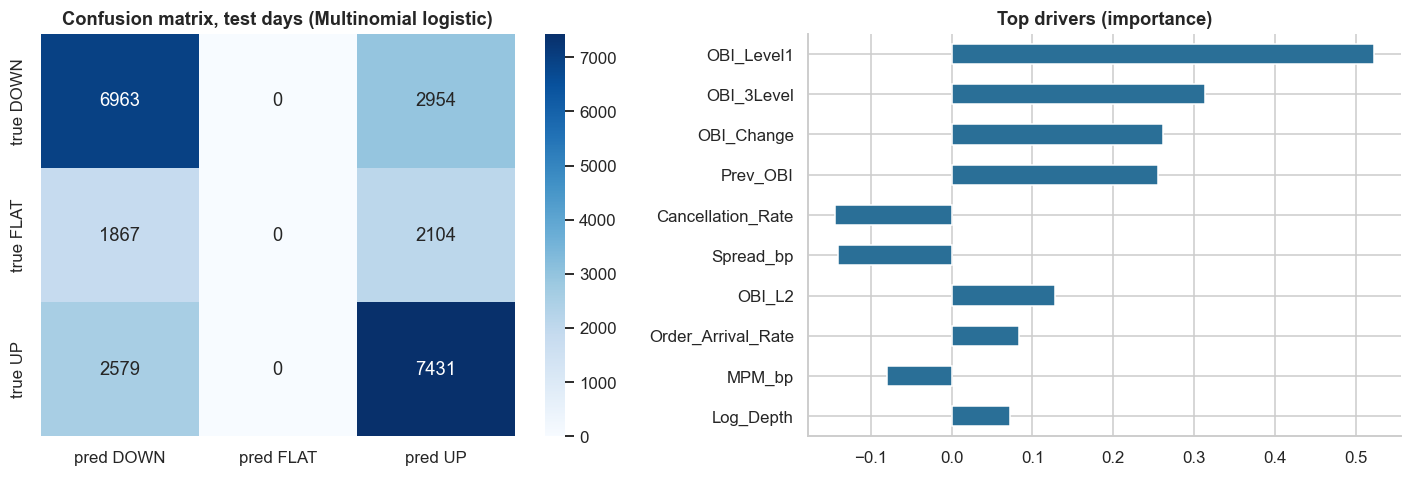

,importance
OBI_Level1,0.5234
OBI_3Level,0.3139
OBI_Change,0.2613
Prev_OBI,0.2553
Cancellation_Rate,-0.1441
Spread_bp,-0.1411
OBI_L2,0.1284
Order_Arrival_Rate,0.0828
MPM_bp,-0.0807
Log_Depth,0.0717


In [15]:
yhat = np.array(CLASSES)[test_proba[chosen].argmax(1)]
cm = pd.DataFrame(confusion_matrix(test.Price_Move_Class, yhat, labels=CLASSES), index=[f'true {c}' for c in CLASSES],
                  columns=[f'pred {c}' for c in CLASSES])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0]); ax[0].set_title(f'Confusion matrix, test days ({chosen})')
if chosen == 'Multinomial logistic':
    coef = pd.DataFrame(fitted[chosen][-1].coef_, index=CLASSES, columns=FEATURES).T      # one column per class
    imp = (coef['UP'] - coef['DOWN']).sort_values(key=np.abs, ascending=False)            # UP-vs-DOWN push per 1 std
else:
    from sklearn.inspection import permutation_importance
    pi = permutation_importance(fitted[chosen], test[FEATURES].sample(5000, random_state=SEED),
                                test.Price_Move_Class.sample(5000, random_state=SEED), scoring='f1_macro',
                                n_repeats=3, random_state=SEED, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(key=np.abs, ascending=False)
imp.head(10)[::-1].plot(kind='barh', ax=ax[1], color='#2a6f97'); ax[1].set_title('Top drivers (importance)')
plt.tight_layout(); savefig('hft_model'); plt.show()
imp.head(10).round(4).to_frame('importance')

> ### 📘 Explanation — cell 23
> **Trading rule.** Long if P(UP) > θ, short if P(DOWN) > θ, else no trade; close after 100 ms.
> Net bp = direction × next return − (**full spread** + 0.5 bp fee) — conservative: we cross the spread both ways.
> θ chosen on validation (max total net profit), frozen for test.

## 5. From probabilities to a trading signal (ML Task 2)
**Rule.** Go **long** if P(UP) > θ, **short** if P(DOWN) > θ, otherwise do nothing. Each trade is closed after 100 ms.

**Profit per trade (bp)** = direction × next 100 ms mid return − cost, where
cost = the **full quoted spread** (we buy at the ask and sell at the bid, or the reverse) + 0.5 bp fees.

θ is chosen on the **validation** days (maximum total net profit) and then frozen for the **test** days.

> ### 📘 Explanation — cell 24
> **What it does.** `trades()` builds the list of trades with gross, cost and net bp; options `cost_mult` (cost stress) and
> `delay` (use the signal from k events earlier = latency stress). `summary()` → trades/day, hit rate, gross/net bp per
> trade, net ₹ lakh/day (at ₹10 lakh notional), annualised daily Sharpe.

In [16]:
def trades(df, proba, theta, cost_mult=1.0, delay=0):
    """Trades taken by the threshold rule; returns a DataFrame with net bp per trade.
    delay=k: the signal from k events earlier (same stock and day) is used, i.e. we react late."""
    p = pd.DataFrame(proba, columns=CLASSES, index=df.index)
    if delay:
        p = p.groupby([df.Day, df.Stock]).shift(delay)                        # stale signal
    side = np.where(p.UP > theta, 1, np.where(p.DOWN > theta, -1, 0))        # +1 long, -1 short, 0 no trade
    t = df.loc[side != 0, ['Day', 'Stock', 'Future_Return_100ms', 'Spread_bp']].copy()
    t['Side'] = side[side != 0]
    t['Gross_bp'] = t.Side * t.Future_Return_100ms * 1e4                      # what the move paid
    t['Cost_bp'] = cost_mult * (t.Spread_bp + FEE_BP)                          # what crossing the spread + fees cost
    t['Net_bp'] = t.Gross_bp - t.Cost_bp
    return t

def summary(t, n_days):
    """Daily P&L statistics for a set of trades at NOTIONAL rupees each."""
    if len(t) == 0:
        return {'Trades/day': 0, 'Hit rate': np.nan, 'Gross bp/trade': np.nan, 'Net bp/trade': np.nan,
                'Net ₹ lakh/day': 0.0, 'Daily Sharpe (ann.)': np.nan}
    daily_pnl = t.groupby('Day').Net_bp.sum() * NOTIONAL / 1e4                  # ₹ per day
    return {'Trades/day': len(t) / n_days, 'Hit rate': (t.Net_bp > 0).mean(), 'Gross bp/trade': t.Gross_bp.mean(),
            'Net bp/trade': t.Net_bp.mean(), 'Net ₹ lakh/day': daily_pnl.mean() / 1e5,
            'Daily Sharpe (ann.)': daily_pnl.mean() / daily_pnl.std() * np.sqrt(252) if daily_pnl.std() > 0 else np.nan}

> ### 📘 Explanation — cell 25
> **What it does.** Scans θ from 0.40 to 0.95 on validation.
>
> **Output.** θ = 0.40: 5,994 trades/day, 0.84 bp net; **θ = 0.55: 3,965 trades/day, hit 63%, 1.69 bp net, ₹6.68 lakh/day
> (max total ₹26.7 lakh)**; θ = 0.75: 698 trades/day, 3.0 bp net but less total.
>
> **How to read.** Higher θ = fewer but better trades; total profit peaks at 0.55 (quality × quantity trade-off).

In [17]:
thetas = np.round(np.arange(0.40, 0.96, 0.05), 2)                                  # candidate thresholds
scan = pd.DataFrame({th: summary(trades(val, val_proba[chosen], th), len(val_days)) for th in thetas}).T
scan['Total net ₹ lakh'] = scan['Net ₹ lakh/day'] * len(val_days)
theta = float(scan['Total net ₹ lakh'].idxmax())                                  # best threshold on validation
print('threshold chosen on validation days:', theta)
scan.round(3)

threshold chosen on validation days: 0.55


,Trades/day,Hit rate,Gross bp/trade,Net bp/trade,Net ₹ lakh/day,Daily Sharpe (ann.),Total net ₹ lakh
0.40,5993.75,0.566,2.694,0.839,5.030,78.838,20.119
0.45,5347.75,0.587,2.981,1.102,5.892,98.110,23.568
0.50,4671.75,0.608,3.294,1.385,6.468,116.939,25.873
0.55,3964.75,0.634,3.621,1.685,6.682,121.214,26.727
0.60,3229.00,0.654,3.953,1.986,6.414,122.796,25.657
0.65,2398.50,0.679,4.299,2.299,5.515,121.284,22.060
0.70,1505.00,0.708,4.771,2.701,4.065,89.191,16.261
0.75,698.00,0.721,5.288,2.995,2.090,65.055,8.361
0.80,215.50,0.716,6.373,3.425,0.738,38.293,2.952
0.85,31.25,0.608,6.539,2.440,0.076,19.985,0.305


> ### 📘 Explanation — cell 26
> **What it does.** On test days, each model at its own validation-optimal θ vs the OBI-sign rule.
>
> **Output.** GB ₹6.32 lakh/day, **logistic ₹6.30**, RF ₹6.23, OBI rule **₹4.64** (more trades, 0.78 bp net).
>
> **How to read.** ML adds ~₹1.7 lakh/day over the rule by trading *more selectively* (better probabilities). GB vs logistic
> difference (₹0.02 lakh) is negligible → logistic kept. Sharpe ratios from 4 days are not meaningful.

In [18]:
# Test days: chosen model vs other models vs the one-feature rule, each at its own validation-optimal threshold
sig_rows = {}
for name in order:
    vs = pd.DataFrame({th: summary(trades(val, val_proba[name], th), len(val_days)) for th in thetas}).T
    th_n = float((vs['Net ₹ lakh/day']).idxmax())                                   # each model's own best threshold
    sig_rows[name] = {'threshold': th_n, **summary(trades(test, test_proba[name], th_n), len(test_days))}
rule_test = np.where(test.OBI_Level1.values[:, None] > 0, [0.0, 0.0, 1.0], [1.0, 0.0, 0.0])
sig_rows['Rule: sign of OBI'] = {'threshold': 0.5, **summary(trades(test, rule_test, 0.5), len(test_days))}
sig_tbl = pd.DataFrame(sig_rows).T
compare_models(sig_tbl, 'Net ₹ lakh/day', chosen=chosen, baseline='Rule: sign of OBI',
               extra=['threshold', 'Trades/day', 'Hit rate', 'Gross bp/trade', 'Net bp/trade', 'Daily Sharpe (ann.)']).round(3)

,Rank,Net ₹ lakh/day,threshold,Trades/day,Hit rate,Gross bp/trade,Net bp/trade,Daily Sharpe (ann.),Gain vs baseline,Gap to best,Chosen
Gradient boosting,1,6.319,0.55,3817.25,0.624,3.557,1.656,817.628,1.676,0.000,
Multinomial logistic,2,6.303,0.55,3811.50,0.624,3.527,1.654,447.251,1.660,0.017,✔
Random forest,3,6.226,0.55,3836.75,0.621,3.525,1.623,539.220,1.582,0.094,
Rule: sign of OBI,4,4.643,0.50,5974.50,0.556,2.572,0.777,186.475,0.000,1.676,


> ### 📘 Explanation — cell 27
> **Stress design.** Costs ×2 and ×3 (wider spreads, worse fees, partial fills); latency 1 and 3 events; combined costs ×2 + 1-event delay.

## 6. Stress test: does the edge survive real-world frictions?
- **Costs × 2 and × 3** (wider spreads in fast markets, worse fees, partial fills).
- **Latency**: we act on the signal from 1 or 3 events earlier (our order arrives late).
- **Combined**: costs × 2 and a 1-event delay.

> ### 📘 Explanation — cell 28
> **What it does.** Re-runs the base strategy under each friction.
>
> **Output (₹ lakh/day).** Base **+6.30** · costs ×2 **−0.84** · costs ×3 −7.98 · delay 1 **−1.06** · delay 3 −4.08 · both −8.03.
>
> **How to read.** The edge (1.65 bp) is about the size of one spread — so doubling costs or being one event late wipes it
> out. **Decisive result: prop HFT does not survive realistic frictions.**

In [19]:
base_t = trades(test, test_proba[chosen], theta)
stress = {'Base': summary(base_t, len(test_days)),
          'Costs x2': summary(trades(test, test_proba[chosen], theta, cost_mult=2), len(test_days)),
          'Costs x3': summary(trades(test, test_proba[chosen], theta, cost_mult=3), len(test_days)),
          'Delay 1 event': summary(trades(test, test_proba[chosen], theta, delay=1), len(test_days)),
          'Delay 3 events': summary(trades(test, test_proba[chosen], theta, delay=3), len(test_days)),
          'Costs x2 + delay 1': summary(trades(test, test_proba[chosen], theta, cost_mult=2, delay=1), len(test_days))}
stress = pd.DataFrame(stress).T
stress.round(3)

,Trades/day,Hit rate,Gross bp/trade,Net bp/trade,Net ₹ lakh/day,Daily Sharpe (ann.)
Base,3811.50,0.624,3.527,1.654,6.303,447.251
Costs x2,3811.50,0.484,3.527,-0.220,-0.839,-62.798
Costs x3,3811.50,0.365,3.527,-2.094,-7.980,-498.180
Delay 1 event,3804.75,0.481,1.550,-0.280,-1.064,-27.367
Delay 3 events,3792.75,0.429,0.719,-1.075,-4.077,-332.417
Costs x2 + delay 1,3804.75,0.363,1.550,-2.110,-8.028,-221.806


> ### 📘 Explanation — cell 29
> **What it does.** Cumulative test-day P&L for base and stressed cases, and histogram of net bp per trade (`hft_pnl.png`). Shows the base line rising and stressed lines falling.

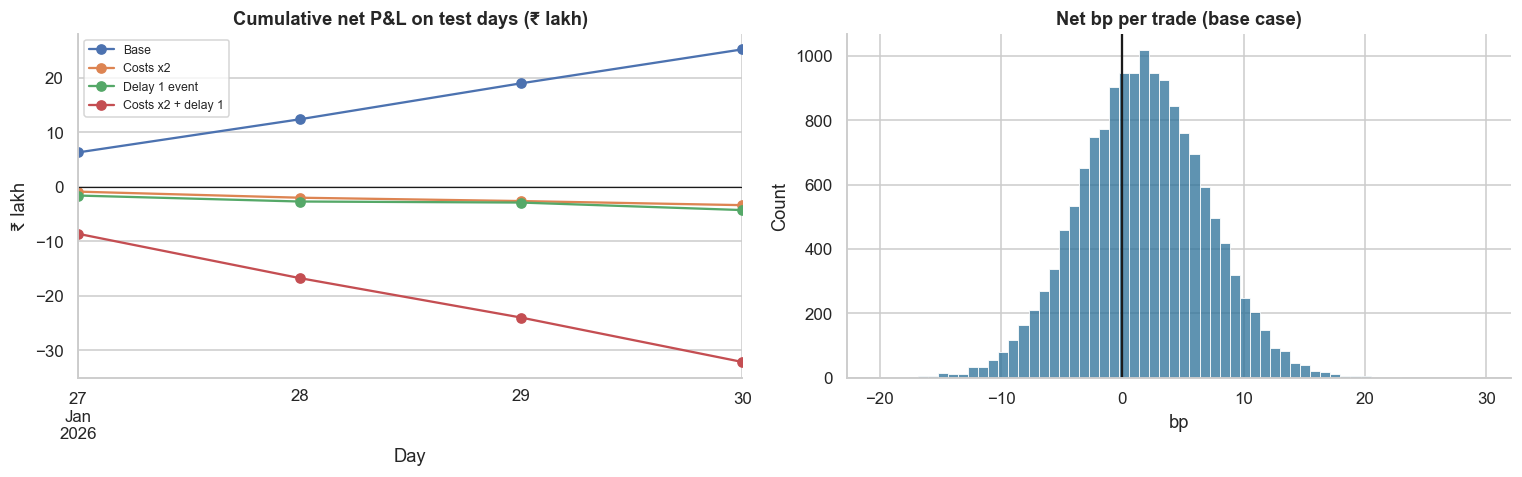

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, kw in [('Base', {}), ('Costs x2', {'cost_mult': 2}), ('Delay 1 event', {'delay': 1}), ('Costs x2 + delay 1', {'cost_mult': 2, 'delay': 1})]:
    t = trades(test, test_proba[chosen], theta, **kw)
    (t.groupby('Day').Net_bp.sum() * NOTIONAL / 1e4 / 1e5).cumsum().plot(ax=ax[0], marker='o', label=name)
ax[0].axhline(0, c='k', lw=0.8); ax[0].set(title='Cumulative net P&L on test days (₹ lakh)', ylabel='₹ lakh'); ax[0].legend(fontsize=8)
sns.histplot(base_t.Net_bp, bins=60, ax=ax[1], color='#2a6f97'); ax[1].axvline(0, c='k')
ax[1].set(title='Net bp per trade (base case)', xlabel='bp')
plt.tight_layout(); savefig('hft_pnl'); plt.show()

> ### 📘 Explanation — cell 30
> **Execution use.** Even without prop trading, the signal can *time* child orders of a large client order: buy when P(UP) is high (before the price rises), wait when it is low.

## 7. Execution use: improving large orders
Even without proprietary trading, the signal helps the desk **time** a large order: buy when the model predicts UP
soon (avoid paying more later), wait when it predicts DOWN. A simple test: for every event where the desk must buy,
compare the next-100 ms move when it follows the model (buys only when P(UP) is highest) vs buying at random.

> ### 📘 Explanation — cell 31
> **What it does.** Average next move when P(UP) is in the top 30% ("buy now") vs bottom 30% ("wait") vs all events.
>
> **Output.** Buy now **+3.42 bp**, wait **−3.85 bp**, random −0.05 bp.
>
> **How to read.** ≈ 7 bp timing benefit per child order; it does not require crossing the spread for profit, so it is
> far more robust to costs than prop trading (connects to VWAP-style execution).

In [21]:
p_up = test_proba[chosen][:, CLASSES.index('UP')]
follow = test.Future_Return_100ms.values[p_up >= np.quantile(p_up, 0.7)] * 1e4      # buy when UP is most likely
avoid = test.Future_Return_100ms.values[p_up <= np.quantile(p_up, 0.3)] * 1e4       # these are the moments to wait
print(f'average next move when the model says "buy now": {follow.mean():+.2f} bp')
print(f'average next move when the model says "wait"   : {avoid.mean():+.2f} bp')
print(f'average next move at random                    : {test.Future_Return_100ms.mean() * 1e4:+.2f} bp')

average next move when the model says "buy now": +3.42 bp
average next move when the model says "wait"   : -3.85 bp
average next move at random                    : -0.05 bp


> ### 📘 Explanation — cell 32
> **Reading.** Execution saving is the robust business use of the signal.

**Reading.** Buying when the model says "buy now" means buying just *before* the price rises; waiting avoids buying
just before it falls. The difference, a few bp per child order, is a direct **execution saving** on large orders.
It does not require crossing the spread for profit, so it survives costs far better than proprietary trading.

> ### 📘 Explanation — cell 33
> **Section header** – hand-off.

## 8. Hand-off to notebook 10

> ### 📘 Explanation — cell 34
> **What it does.** Saves `hft.json`: assumptions, model choice, validation/test reports, signal comparison, stress table,
> execution saving (bp), base vs stressed P&L and an allocation note (small capacity-limited pilot with hard loss limits).

In [22]:
b = stress.loc['Base']; s2 = stress.loc['Costs x2 + delay 1']
res = {'module': 'hft',
       'assumptions': {'fee_bp_round_trip': FEE_BP, 'notional_per_trade_inr': NOTIONAL, 'theta': theta,
                       'split_days': {'train': 12, 'validation': 4, 'test': 4}},
       'model': {'chosen': chosen, 'validation': val_rep.round(4).to_dict(orient='index'),
                 'test': test_rep.round(4).to_dict(orient='index')},
       'signal_test': sig_tbl.round(4).to_dict(orient='index'),
       'stress': stress.round(4).to_dict(orient='index'),
       'execution_saving_bp': float(follow.mean() - test.Future_Return_100ms.mean() * 1e4),
       'base_net_lakh_per_day': b['Net ₹ lakh/day'], 'stressed_net_lakh_per_day': s2['Net ₹ lakh/day'],
       'allocation_note': 'Synthetic order book is unusually generous (moves >> spread). Treat HFT as a small, '
                          'capacity-limited pilot with hard loss limits; main value is execution quality.'}
save_result('hft', res)

saved results/Module_07_HFT/hft.json


> ### 📘 Explanation — cell 35
> **Headline results & limitations** – macro-F1 0.44 ≈ OBI rule; ₹6.3 lakh/day base but negative under stress; ~7 bp execution benefit; recommend at most a ₹10 cr pilot with kill switch. Limitations: generous synthetic market, only 4 test days, no queue position/impact/competition, minute timestamps, regime risk.

## Headline results
- **Data.** 120,000 order-book events, 10 stocks, 20 trading days. FLAT means |100 ms move| < 1.2 bp. Order-book
  imbalance correlates 0.51 with the next move, and the average move (4.7 bp) is 3.5× the spread (1.3 bp).
  This is far more generous than real markets.
- **Direction models (test days, macro-F1).** Logistic 0.438, random forest 0.438, gradient boosting 0.440, all far
  above no-skill (0.20) but **level with the one-line imbalance rule**. The simplest model is chosen. FLAT is never the
  most likely class (recall 0); that does not matter for trading, which only acts on UP/DOWN.
- **Trading signal** (threshold 0.55 chosen on validation days, ₹10 lakh per trade). On the 4 test days: about 3,800
  trades a day, 62% hit rate, 3.5 bp gross and **1.65 bp net per trade**, ₹6.3 lakh a day. The imbalance rule earns
  ₹4.6 lakh a day, so ML adds about ₹1.7 lakh a day by trading more selectively.
- **Stress (decisive).** Doubling costs turns the result to −₹0.8 lakh a day; reacting one event late gives −₹1.1 lakh a
  day; both together −₹8.0 lakh a day. **The edge does not survive realistic frictions.**
- **Execution use (robust).** Buying when the model says "buy now" meets a +3.4 bp next move vs −3.9 bp when it says
  "wait", about 7 bp of timing benefit per child order of a large client order, without needing to cross the spread for profit.
- **Decision for notebook 10:** no material capital for proprietary HFT. At most a **₹10 crore pilot** with a kill switch;
  use the signal mainly inside the **execution algorithm**.
- *Note:* annualised Sharpe ratios from 4 test days are not meaningful and are shown only for completeness.

## Risks and limitations
- **Synthetic market:** the next move is several times the spread and imbalance predicts it strongly. Real markets
  are far less generous; the stressed numbers are the ones to plan with.
- Only 20 trading days (4 test days): P&L statistics are very noisy.
- No queue position, partial fills, market impact or competition from faster traders; latency is approximated by
  using stale signals.
- Timestamps are only to the minute, so true event timing within a minute is unknown.
- Model risk: a regime change (volatility spike) can flip the signal; requires real-time monitoring and a kill switch.